In [9]:
import sys
import os
sys.path.append(os.path.abspath(".."))
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_data

sns.set_style("whitegrid")
%matplotlib inline

In [10]:
df = load_data()
print("Shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
print("\nClass balance:")
print(df["class"].value_counts())
print(f"\nPositive rate: {df['class'].mean():.4%}")

Shape: (17898, 9)

Missing values: 0

Class balance:
class
0    16259
1     1639
Name: count, dtype: int64

Positive rate: 9.1574%


In [11]:
features = [c for c in df.columns if c != "class"]

print("=== Overall ===")
print(df[features].describe().T[["mean", "std", "min", "max"]])

print("\n=== By class (means) ===")
print(df.groupby("class")[features].mean().T)

=== Overall ===
                      mean         std        min          max
mean_ip         111.079968   25.652935   5.812500   192.617188
std_ip           46.549532    6.843189  24.772042    98.778911
skewness_ip       0.477857    1.064040  -1.876011     8.069522
kurtosis_ip       1.770279    6.167913  -1.791886    68.101622
mean_dmsnr       12.614400   29.472897   0.213211   223.392141
std_dmsnr        26.326515   19.470572   7.370432   110.642211
skewness_dmsnr    8.303556    4.506092  -3.139270    34.539844
kurtosis_dmsnr  104.857709  106.514540  -1.976976  1191.000837

=== By class (means) ===
class                    0          1
mean_ip         116.562726  56.690608
std_ip           47.339741  38.710598
skewness_ip       0.210440   3.130655
kurtosis_ip       0.380844  15.553576
mean_dmsnr        8.863258  49.825995
std_dmsnr        23.287984  56.468963
skewness_dmsnr    8.862674   2.757069
kurtosis_dmsnr  113.620344  17.931728


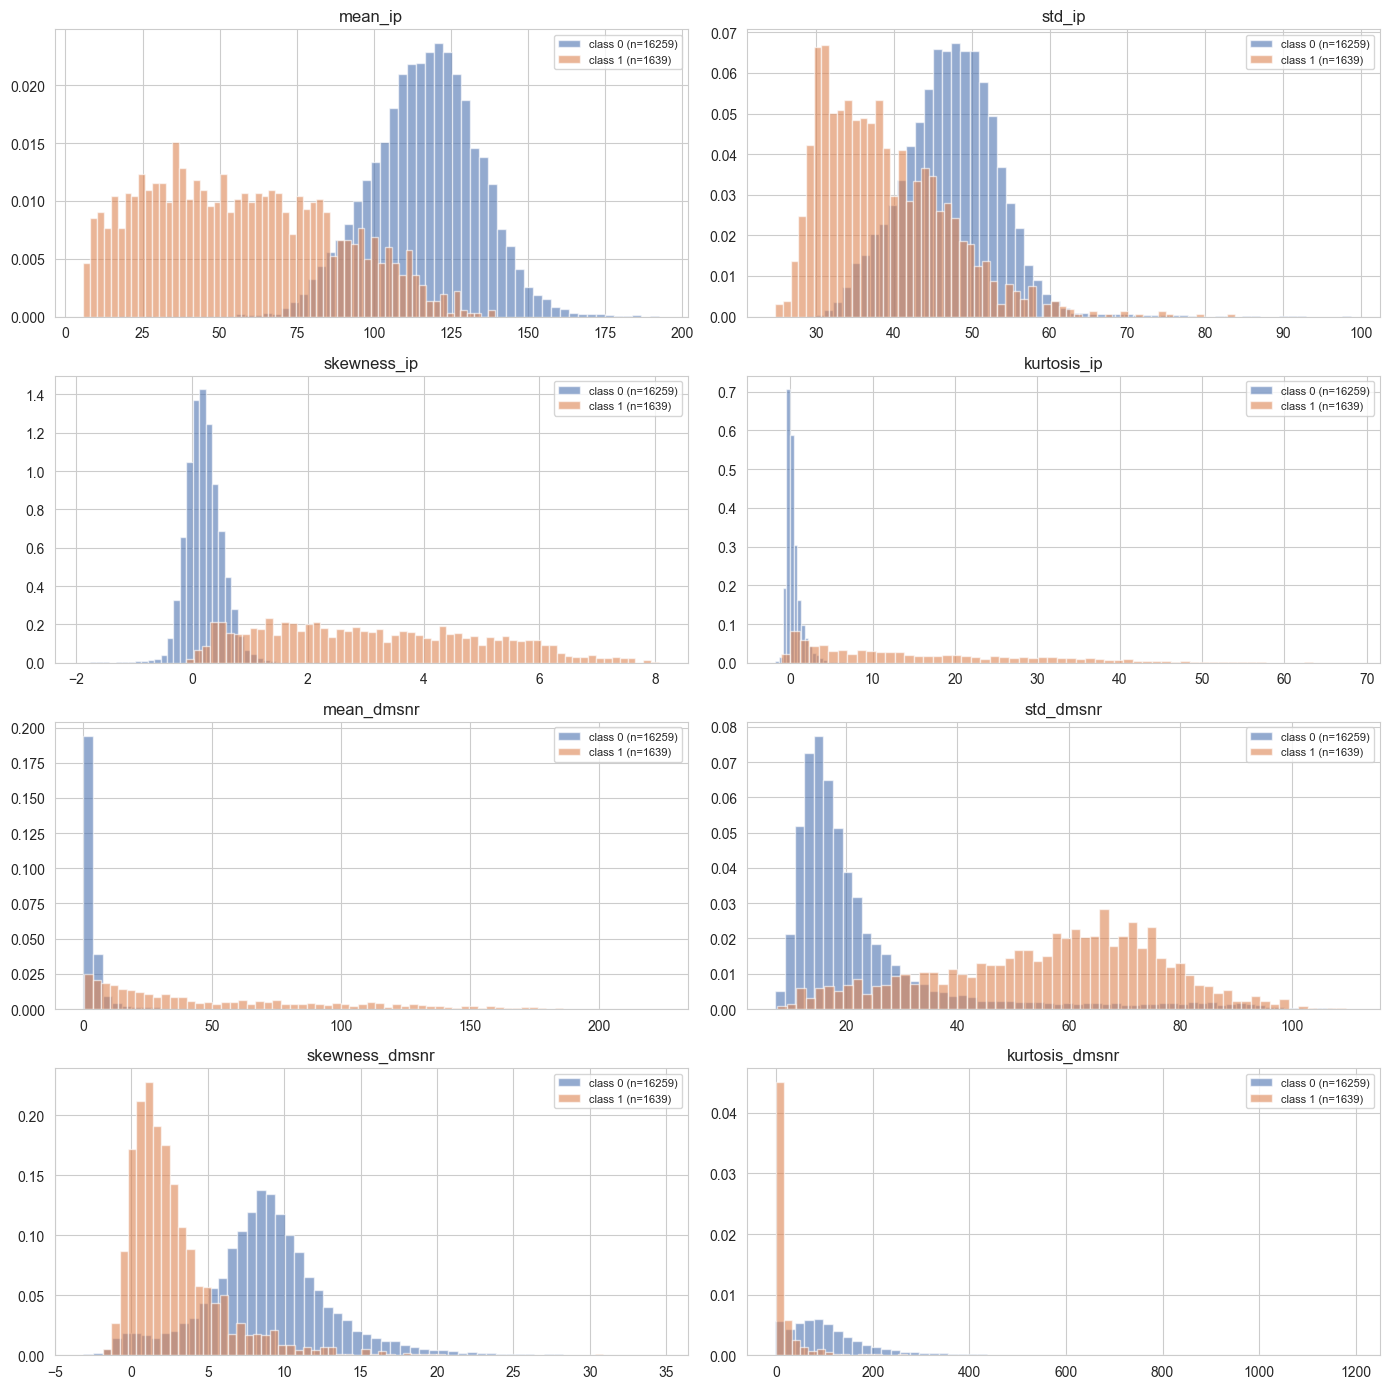

In [12]:
fig, axes = plt.subplots(4, 2, figsize=(14, 14))
axes = axes.ravel()

for i, col in enumerate(features):
    for cls, color in zip([0, 1], ["#4C72B0", "#DD8452"]):
        subset = df[df["class"] == cls][col]
        axes[i].hist(subset, bins=60, alpha=0.6,
                     label=f"class {cls} (n={len(subset)})",
                     color=color, density=True)
    axes[i].set_title(col)
    axes[i].legend(fontsize=8)

plt.tight_layout()
plt.savefig("../results/feature_distributions.png", dpi=100, bbox_inches="tight")
plt.show()


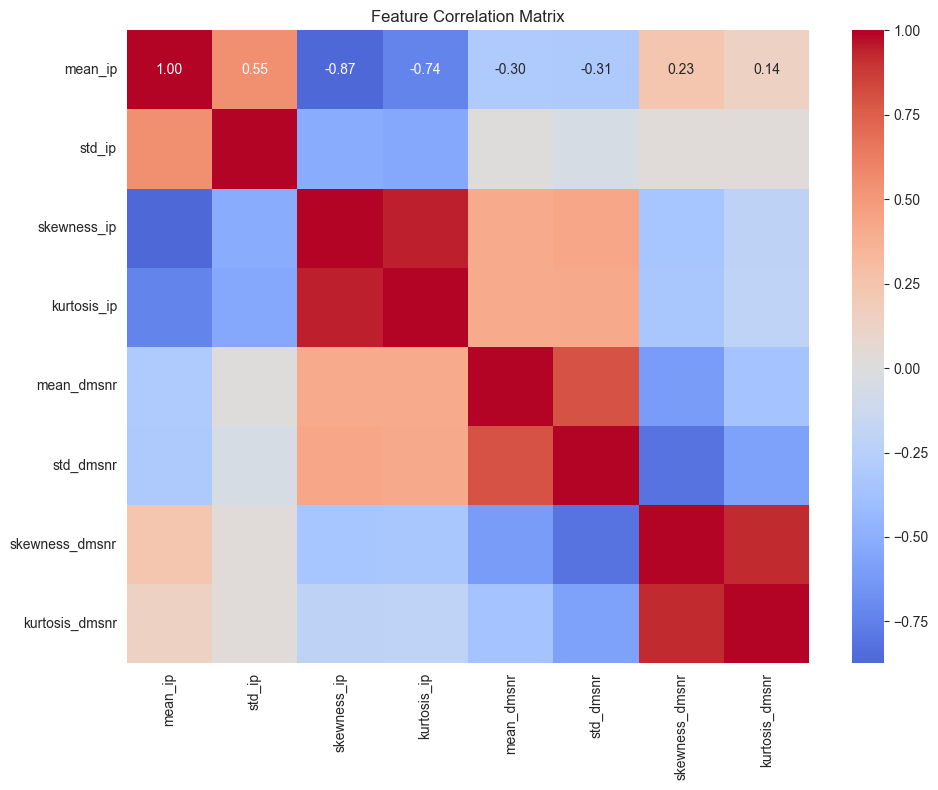

In [5]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.savefig("../results/correlation_matrix.png", dpi=100)
plt.show()

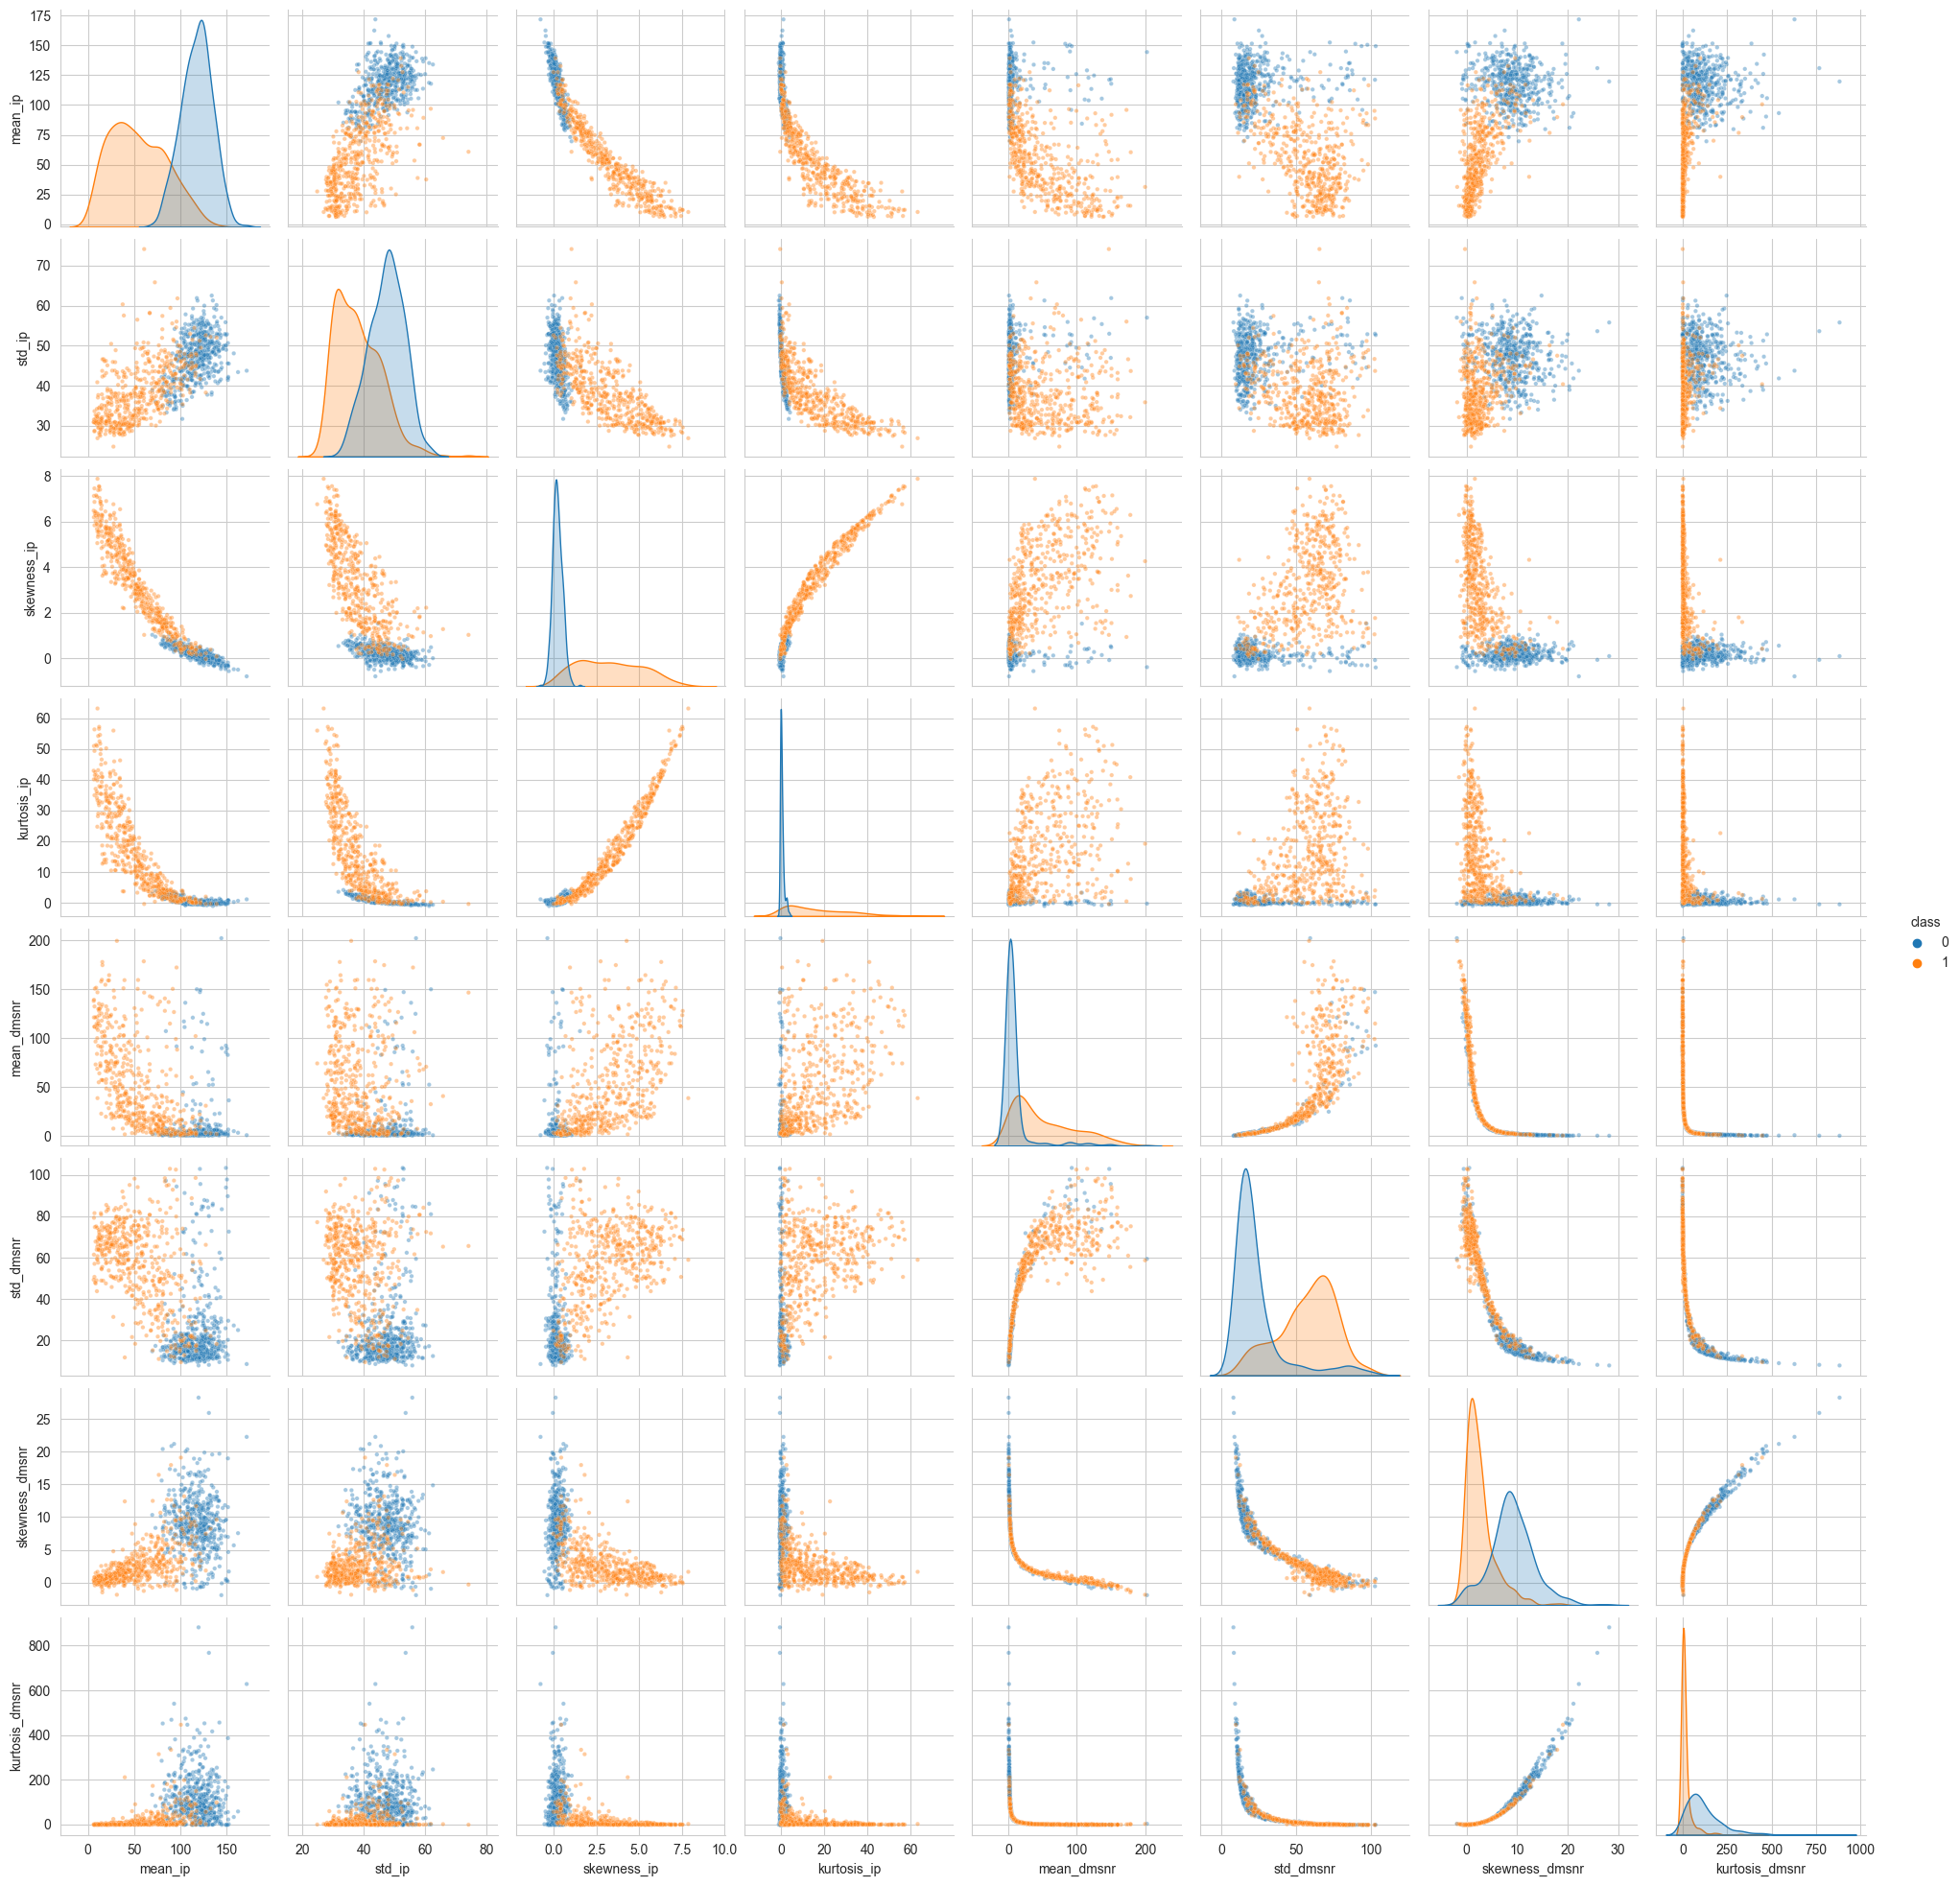

In [13]:
sample = df.groupby("class", group_keys=False).apply(
    lambda x: x.sample(min(len(x), 500), random_state=42)
)
sns.pairplot(sample, hue="class", diag_kind="kde", plot_kws={"alpha": 0.4, "s": 10})
plt.savefig("../results/pairplot.png", dpi=100)
plt.show()

In [14]:
import os
print(os.listdir("../results"))


['correlation_matrix.png', 'feature_distributions.png', 'pairplot.png']
